# 01 - Fundamentos de KNN en Regresión y Esquemas de Ponderación

## Curso de Machine Learning: Modelos de Regresión

El algoritmo **K-Nearest Neighbors (K-Vecinos Más Cercanos - KNN)** es un modelo no paramétrico de **aprendizaje perezoso (Lazy Learning)**. En lugar de ajustar coeficientes globales como en la regresión lineal, predice el valor de una nueva observación promediando localmente los valores continuos de sus vecinos geométricamente más próximos.

---

### Contenidos
1. Formulación Matemática de KNN para Variables Continuas
2. Esquemas de Ponderación: Promedio Uniforme (`uniform`) vs. Ponderado por Distancia (`distance`)
3. Demostración Visual 1D: Interpolación y Transición de Curvas
4. El Rol Imprescindible del Escalado de Características (`StandardScaler`)
5. Ajuste con `KNeighborsRegressor` en el Dataset Auto MPG
6. Conclusiones


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
np.random.seed(42)
print("Entorno listo.")


Entorno listo.


## 1. Formulación Matemática de KNN en Regresión

Dado un conjunto de entrenamiento $\mathcal{D} = \{(\mathbf{x}_i, y_i)\}_{i=1}^N$ con $y_i \in \mathbb{R}$, para predecir en un nuevo punto $\mathbf{x}^*$:
1. Se calculan las distancias $d(\mathbf{x}^*, \mathbf{x}_i)$ en el espacio $\mathbb{R}^D$ (habitualmente distancia Euclidiana o Manhattan).
2. Se identifica el conjunto de los $K$ vecinos más cercanos: $\mathcal{N}_K(\mathbf{x}^*)$.
3. Se estima el valor de salida:

### A. Votación Uniforme (`weights='uniform'`):
$$\hat{y}(\mathbf{x}^*) = \frac{1}{K} \sum_{i \in \mathcal{N}_K(\mathbf{x}^*)} y_i$$

### B. Votación Ponderada por Inverso de la Distancia (`weights='distance'`):
$$\hat{y}(\mathbf{x}^*) = \frac{\sum_{i \in \mathcal{N}_K(\mathbf{x}^*)} w_i y_i}{\sum_{i \in \mathcal{N}_K(\mathbf{x}^*)} w_i}, \quad \text{donde } w_i = \frac{1}{d(\mathbf{x}^*, \mathbf{x}_i)}$$


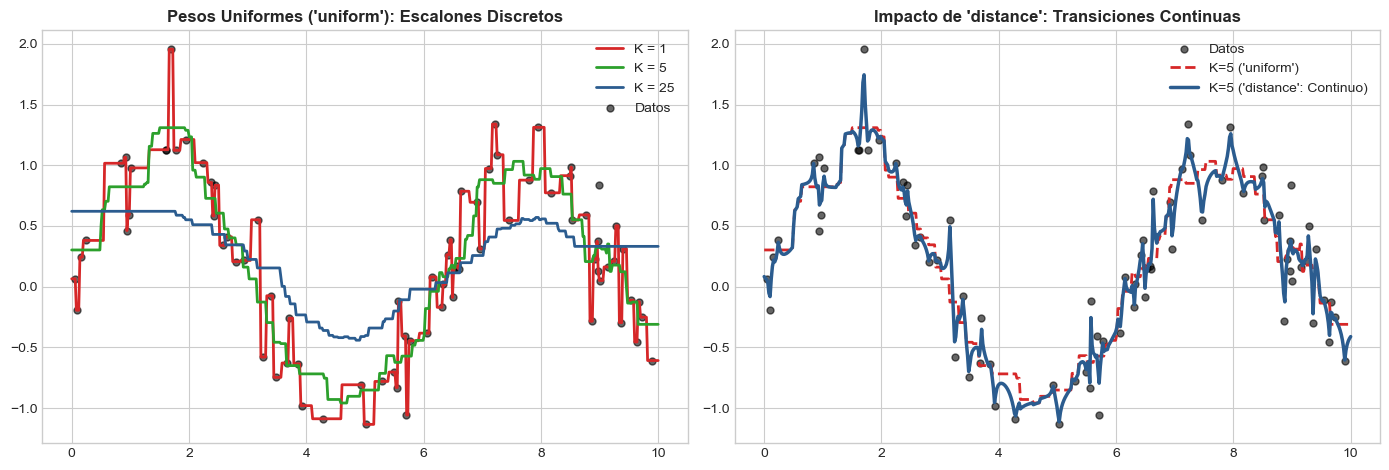

In [5]:
# Demostracion 1D: Comparativa de Suavizado y Pesos
# Generamos una funcion no lineal ruidosa
X_demo = np.sort(np.random.uniform(0, 10, 80)).reshape(-1, 1)
y_demo = np.sin(X_demo).ravel() + np.random.normal(0, 0.25, X_demo.shape[0])

x_plot = np.linspace(0, 10, 500).reshape(-1, 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# 1. Efecto de K con pesos uniformes
for k, col in zip([1, 5, 25], ['#d62728', '#2ca02c', '#2b5c8f']):
    knn_u = KNeighborsRegressor(n_neighbors=k, weights='uniform').fit(X_demo, y_demo)
    axes[0].plot(x_plot, knn_u.predict(x_plot), label=f'K = {k}', color=col, lw=2)

axes[0].scatter(X_demo, y_demo, color='black', s=25, alpha=0.6, label='Datos')
axes[0].set_title("Pesos Uniformes ('uniform'): Escalones Discretos", fontweight='bold')
axes[0].legend()

# 2. Pesos por distancia vs uniforme (K=5)
knn_unif = KNeighborsRegressor(n_neighbors=5, weights='uniform').fit(X_demo, y_demo)
knn_dist = KNeighborsRegressor(n_neighbors=5, weights='distance').fit(X_demo, y_demo)

axes[1].scatter(X_demo, y_demo, color='black', s=25, alpha=0.6, label='Datos')
axes[1].plot(x_plot, knn_unif.predict(x_plot), '--', color='#d62728', lw=2, label="K=5 ('uniform')")
axes[1].plot(x_plot, knn_dist.predict(x_plot), '-', color='#2b5c8f', lw=2.5, label="K=5 ('distance': Continuo)")
axes[1].set_title("Impacto de 'distance': Transiciones Continuas", fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()


## 2. El Impacto Crítico del Escalado en Regresión

Al igual que en clasificación, KNN calcula distancias numéricas directas. Si una variable tiene magnitudes del orden de miles (ej. peso del auto en libras: $3,000$ lbs) y otra del orden de unidades (ej. cilindros: $4$ a $8$), la variable con mayor escala absorberá prácticamente toda la distancia euclidiana.


In [7]:
# Carga de Auto MPG
df = pd.read_csv("../../../data/auto_mpg.csv")
features = ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']
X = df[features]
y = df['mpg']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Experimento: Sin Escalado vs Con StandardScaler
knn_raw = KNeighborsRegressor(n_neighbors=5).fit(X_train, y_train)
r2_raw = r2_score(y_test, knn_raw.predict(X_test))
rmse_raw = np.sqrt(mean_squared_error(y_test, knn_raw.predict(X_test)))

pipe_scaled = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsRegressor(n_neighbors=5))
]).fit(X_train, y_train)

r2_scaled = r2_score(y_test, pipe_scaled.predict(X_test))
rmse_scaled = np.sqrt(mean_squared_error(y_test, pipe_scaled.predict(X_test)))

print("="*60)
print(f"KNN SIN Escalado -> R2: {r2_raw:.4f} | RMSE: {rmse_raw:.2f} mpg")
print(f"KNN CON Escalado -> R2: {r2_scaled:.4f} | RMSE: {rmse_scaled:.2f} mpg")
print(f"Mejora en R2: +{(r2_scaled - r2_raw)*100:.2f} puntos porcentuales")
print("="*60)


KNN SIN Escalado -> R2: 0.6524 | RMSE: 4.19 mpg
KNN CON Escalado -> R2: 0.8767 | RMSE: 2.49 mpg
Mejora en R2: +22.44 puntos porcentuales


## 3. Conclusiones

1. **Interpolación Local**: KNN no requiere supuestos sobre la forma funcional (lineal, cuadrática) de la relación entre $X$ e $y$.
2. **Ponderación por Distancia**: `weights='distance'` produce estimaciones continuas y más suaves que eliminan los escalones abruptos de `uniform`.
3. **Escalado Obligatorio**: Nunca debe entrenarse KNN sin haber estandarizado previamente las características con `StandardScaler`.

En el siguiente cuaderno, **02_Hiperparametros_Curva_Validacion_y_Dimensionalidad.ipynb**, evaluaremos el compromiso sesgo-varianza, optimizaremos $K$ y analizaremos la incapacidad de extrapolación de KNN.
